# Análisis exploratorio de datos sobre las horas extraordinarias en España

Este trabajo analiza la evolución de las horas extraordinarias realizadas por la población asalariada en España utilizando datos procedentes de la Encuesta de Población Activa (EPA).

El objetivo es estudiar la evolución temporal de las horas extraordinarias durante varios años y, después, las diferencias entre horas pagadas y no pagadas, así como identificar los grupos y actividades económicas con mayor incidencia durante 2025.

In [47]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)


In [48]:
import os

os.listdir("../Dades")


['Asalariados que hacen horas extras - 65211 (1).tsv',
 'Horas extra pagadas y no pagadas porrama de actividad - 65216 (2) (1).tsv']

## Fuentes de datos

Los datos utilizados en este trabajo proceden de la Encuesta de Población Activa (EPA) elaborada por el Instituto Nacional de Estadística (INE).

Para el análisis se emplearon dos conjuntos de datos descargados desde el portal oficial del INE:

- Asalariados que realizan horas extraordinarias.
- Horas extraordinarias pagadas y no pagadas por rama de actividad económica.

Ambos conjuntos contienen información trimestral y permiten estudiar tanto la evolución temporal de las horas extraordinarias como sus diferencias según actividad económica y tipo de remuneración.

## Hipótesis de trabajo

Antes de realizar el análisis exploratorio se plantean las siguientes hipótesis:

1. El número de asalariados que realizan horas extraordinarias se redujo tras la crisis económica de 2008 y posteriormente mostró una recuperación progresiva.

2. Una parte significativa de las horas extraordinarias realizadas en España no son remuneradas.

3. Existen diferencias relevantes entre sectores económicos en el volumen de horas extraordinarias no pagadas.

A través del análisis exploratorio se comprobará si estas hipótesis se cumplen o si los datos muestran una realidad diferente.

## Carga de los conjuntos de datos

Se utilizan dos conjuntos de datos:

- Asalariados que realizan horas extraordinarias.
- Horas extraordinarias pagadas y no pagadas por actividad económica.

Ambos datasets proceden de la Encuesta de Población Activa (EPA).


In [49]:
df_asalariados = pd.read_csv(
    "../Dades/Asalariados que hacen horas extras - 65211 (1).tsv",
    sep="\t"
)

df_horas = pd.read_csv(
    "../Dades/Horas extra pagadas y no pagadas porrama de actividad - 65216 (2) (1).tsv",
    sep="\t"
)

## Exploración inicial

Antes de comenzar el análisis se realiza una revisión general de la estructura de los datos para conocer su tamaño, variables disponibles y formato de almacenamiento.

In [50]:
df_asalariados.shape
df_horas.shape

(14258, 6)

## Identificación de variables

Se revisan las variables disponibles en cada conjunto de datos con el objetivo de comprender la información contenida y seleccionar aquellas relevantes para el análisis.

In [51]:
df_asalariados.columns


Index(['Sexo', 'Edad', 'Realizan o no, horas extraordinarias', 'Periodo',
       'Total'],
      dtype='str')

In [52]:
df_horas.columns

Index(['Sexo', 'Rama de actividad CNAE 2009',
       'Total de horas extraordinarias realizadas en la semana por los asalariados',
       'Periodo', 'Total', 'Unnamed: 5'],
      dtype='str')

## Exploración de variables categóricas Asalariados

Aquí empiezo a analizar los dos conjuntos de datos por separado. Se analizan las categorías presentes en las principales variables cualitativas para conocer la estructura de la información disponible en el datasheet de asalariados.

In [53]:
df_asalariados["Sexo"].unique()

<StringArray>
['Ambos sexos', 'Hombres', 'Mujeres']
Length: 3, dtype: str

## Limpieza del datasheet de Asalariados

Se detectó que las variables numéricas estaban almacenadas como texto debido al formato numérico español utilizado en los archivos originales.

Además, algunos valores faltantes aparecían representados mediante el símbolo "..", por lo que fue necesario transformarlos a valores nulos antes de realizar cualquier análisis estadístico.

In [54]:
df_asalariados_clean = df_asalariados.copy()

df_asalariados_clean["Total"] = pd.to_numeric(
    df_asalariados_clean["Total"]
        .replace("..", np.nan)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False),
    errors="coerce"
)

In [55]:
df_asalariados_clean.head()

,Sexo,Edad,"Realizan o no, horas extraordinarias",Periodo,Total
0,Ambos sexos,Total,Total,2026T1,19056.2
1,Ambos sexos,Total,Total,2025T4,19159.1
2,Ambos sexos,Total,Total,2025T3,19107.8
3,Ambos sexos,Total,Total,2025T2,18978.6
4,Ambos sexos,Total,Total,2025T1,18499.2


In [56]:
df_asalariados_clean["Total"].dtype

dtype('float64')

## Resumen estadístico de la variable Total en Asalariados

Una vez convertida la variable Total a formato numérico, se realiza una exploración descriptiva para conocer la distribución general de los valores y detectar posibles anomalías.

In [57]:
df_asalariados_clean["Total"].describe()

count    18379.000000
mean       615.826285
std       1881.892886
min          0.000000
25%          7.900000
50%         40.500000
75%        523.650000
max      19159.100000
Name: Total, dtype: float64

## Limpieza del datasheet de Horas extraordinarias

Una vez finalizada la limpieza del dataset de asalariados, se revisa el segundo conjunto de datos para identificar posibles inconsistencias en las variables numéricas y valores faltantes y adaptar el formato numérico a Python.

In [58]:
df_horas.dtypes

Sexo                                                                          str
Rama de actividad CNAE 2009                                                   str
Total de horas extraordinarias realizadas en la semana por los asalariados    str
Periodo                                                                       str
Total                                                                         str
Unnamed: 5                                                                    str
dtype: object

In [59]:
df_horas_clean = df_horas.copy()

df_horas_clean["Total"] = pd.to_numeric(
    df_horas_clean["Total"]
        .replace("..", np.nan)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False),
    errors="coerce"
)

In [60]:
df_horas_clean["Total"].dtype

dtype('float64')

In [61]:
df_horas_clean.head()

,Sexo,Rama de actividad CNAE 2009,Total de horas extraordinarias realizadas en la semana por los asalariados,Periodo,Total,Unnamed: 5
0,Ambos sexos,Total,Total,2025T4,6676.4,6676400
1,Ambos sexos,Total,Total,2025T3,5957.3,5957300
2,Ambos sexos,Total,Total,2025T2,7009.8,7009800
3,Ambos sexos,Total,Total,2025T1,5881.7,5881700
4,Ambos sexos,Total,Total,2024T4,7011.2,7011200


In [62]:
df_horas_clean = df_horas_clean.drop(columns=["Unnamed: 5"])

In [63]:
df_horas_clean.head()


,Sexo,Rama de actividad CNAE 2009,Total de horas extraordinarias realizadas en la semana por los asalariados,Periodo,Total
0,Ambos sexos,Total,Total,2025T4,6676.4
1,Ambos sexos,Total,Total,2025T3,5957.3
2,Ambos sexos,Total,Total,2025T2,7009.8
3,Ambos sexos,Total,Total,2025T1,5881.7
4,Ambos sexos,Total,Total,2024T4,7011.2


In [64]:
df_asalariados_clean.info()
df_horas_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 19890 entries, 0 to 19889
Data columns (total 5 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Sexo                                  19890 non-null  str    
 1   Edad                                  19890 non-null  str    
 2   Realizan o no, horas extraordinarias  19890 non-null  str    
 3   Periodo                               19890 non-null  str    
 4   Total                                 18379 non-null  float64
dtypes: float64(1), str(4)
memory usage: 777.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 14258 entries, 0 to 14257
Data columns (total 5 columns):
 #   Column                                                                      Non-Null Count  Dtype  
---  ------                                                                      --------------  -----  
 0   Sexo                                                                    

In [65]:
df_asalariados_clean.isna().sum()

Sexo                                       0
Edad                                       0
Realizan o no, horas extraordinarias       0
Periodo                                    0
Total                                   1511
dtype: int64

In [66]:
df_horas_clean.isna().sum()

Sexo                                                                            2
Rama de actividad CNAE 2009                                                     2
Total de horas extraordinarias realizadas en la semana por los asalariados      2
Periodo                                                                         2
Total                                                                         949
dtype: int64

In [67]:
df_horas_clean.tail()

,Sexo,Rama de actividad CNAE 2009,Total de horas extraordinarias realizadas en la semana por los asalariados,Periodo,Total
14253,Mujeres,U Actividades de organizaciones y organismos e...,Horas extra no pagadas,2008T3,NaN
14254,Mujeres,U Actividades de organizaciones y organismos e...,Horas extra no pagadas,2008T2,NaN
14255,Mujeres,U Actividades de organizaciones y organismos e...,Horas extra no pagadas,2008T1,NaN
14256,NaN,NaN,NaN,NaN,NaN
14257,NaN,NaN,NaN,NaN,NaN


In [68]:
df_horas_clean = df_horas_clean.dropna(
    subset=[
        "Sexo",
        "Rama de actividad CNAE 2009",
        "Total de horas extraordinarias realizadas en la semana por los asalariados",
        "Periodo"
    ]
)

In [69]:
df_horas_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 14256 entries, 0 to 14255
Data columns (total 5 columns):
 #   Column                                                                      Non-Null Count  Dtype  
---  ------                                                                      --------------  -----  
 0   Sexo                                                                        14256 non-null  str    
 1   Rama de actividad CNAE 2009                                                 14256 non-null  str    
 2   Total de horas extraordinarias realizadas en la semana por los asalariados  14256 non-null  str    
 3   Periodo                                                                     14256 non-null  str    
 4   Total                                                                       13309 non-null  float64
dtypes: float64(1), str(4)
memory usage: 557.0 KB


### Resultado de la limpieza

Se transformó la variable Total al formato numérico para permitir su análisis estadístico. Los valores representados mediante ".." en la fuente original fueron convertidos a NaN.

También se eliminó la columna "Unnamed: 5", que no aportaba información al análisis, y se detectaron dos registros vacíos al final del conjunto de datos de horas extraordinarias, que fueron eliminados.

Tras la limpieza, las variables categóricas no presentan valores nulos y los únicos NaN restantes corresponden a datos no disponibles en la fuente original del INE.

# Análisis exploratorio

Una vez completado el proceso de limpieza, se realiza un análisis exploratorio para identificar patrones en la evolución de las horas extraordinarias en España, desde 2005 a 2025 así como las diferencias entre horas pagadas y no pagadas de 2025.

## Evolución de las horas extraordinarias

In [70]:
df_evolucion = df_asalariados_clean[
    (df_asalariados_clean["Sexo"] == "Ambos sexos") &
    (df_asalariados_clean["Edad"] == "Total") &
    (df_asalariados_clean["Realizan o no, horas extraordinarias"] == "Realizan horas extra: Total")
].copy()

df_evolucion = df_evolucion[
    df_evolucion["Periodo"] != "2026T1"
]

In [71]:
df_evolucion = df_evolucion.sort_values("Periodo")

### Evolución de los asalariados que realizan horas extraordinarias

Para estudiar la evolución temporal del fenómeno se seleccionan únicamente los registros de ambos sexos, todas las edades y la categoría "Realizan horas extra: Total". De este modo se obtiene una serie trimestral entre 2005 y 2026.

In [72]:
import matplotlib.pyplot as plt


In [73]:
df_evolucion["Año"] = df_evolucion["Periodo"].str[:4].astype(int)

df_evolucion["Trimestre"] = (
    df_evolucion["Periodo"]
    .str.extract(r'T(\d)')
    .astype(int)
)

In [74]:
df_evolucion = df_evolucion.sort_values("Periodo").reset_index(drop=True)

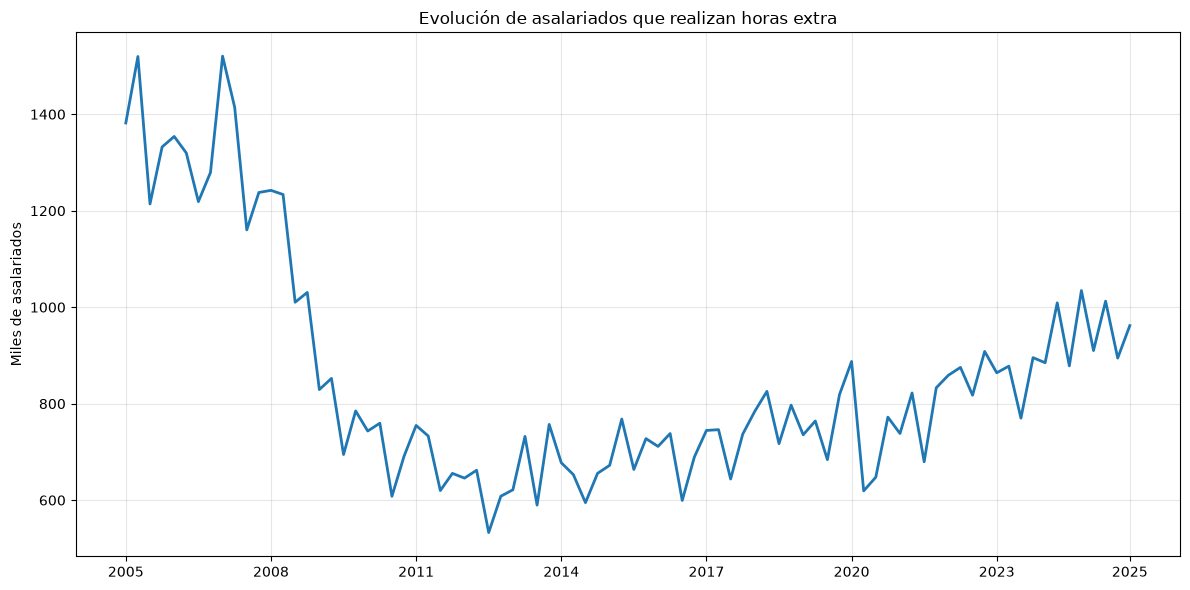

In [75]:
plt.figure(figsize=(12,6))

plt.plot(
    df_evolucion["Total"],
    linewidth=2
)

plt.title("Evolución de asalariados que realizan horas extra")
plt.ylabel("Miles de asalariados")

ticks = list(range(0, len(df_evolucion), 12))
ticks.append(len(df_evolucion) - 1)

plt.xticks(
    ticks=ticks,
    labels=df_evolucion["Año"].iloc[ticks]
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación

La serie muestra una reducción muy significativa del número de asalariados que realizaban horas extraordinarias tras la crisis económica de 2008. Sin embargo, a partir de la década de 2020 se observa una recuperación progresiva hasta acercarse nuevamente al millón de trabajadores.

Este comportamiento sugiere que las horas extraordinarias siguen siendo una práctica habitual en el mercado laboral español, aunque con niveles inferiores a los registrados antes de la crisis.

## Evolución de las horas extraordinarias pagadas y no pagadas

Tras analizar la evolución del número de trabajadores que realizan horas extraordinarias, se estudia el volumen total de horas extra realizadas cada semana y su distribución entre horas remuneradas y no remuneradas.

In [76]:
df_pagadas_nopagadas = df_horas_clean[
    (df_horas_clean["Sexo"] == "Ambos sexos") &
    (df_horas_clean["Rama de actividad CNAE 2009"] == "Total")
].copy()

In [79]:
df_pagadas_nopagadas[
    "Total de horas extraordinarias realizadas en la semana por los asalariados"
].unique()

<StringArray>
['Total', 'Horas extra pagadas', 'Horas extra no pagadas']
Length: 3, dtype: str

In [80]:
df_pagadas = df_pagadas_nopagadas[
    df_pagadas_nopagadas[
        "Total de horas extraordinarias realizadas en la semana por los asalariados"
    ] == "Horas extra pagadas"
].copy()

In [81]:
df_no_pagadas = df_pagadas_nopagadas[
    df_pagadas_nopagadas[
        "Total de horas extraordinarias realizadas en la semana por los asalariados"
    ] == "Horas extra no pagadas"
].copy()

In [82]:
df_pagadas = df_pagadas.sort_values("Periodo").reset_index(drop=True)

df_no_pagadas = df_no_pagadas.sort_values("Periodo").reset_index(drop=True)

In [83]:
df_pagadas["Año"] = df_pagadas["Periodo"].str[:4].astype(int)

df_no_pagadas["Año"] = df_no_pagadas["Periodo"].str[:4].astype(int)

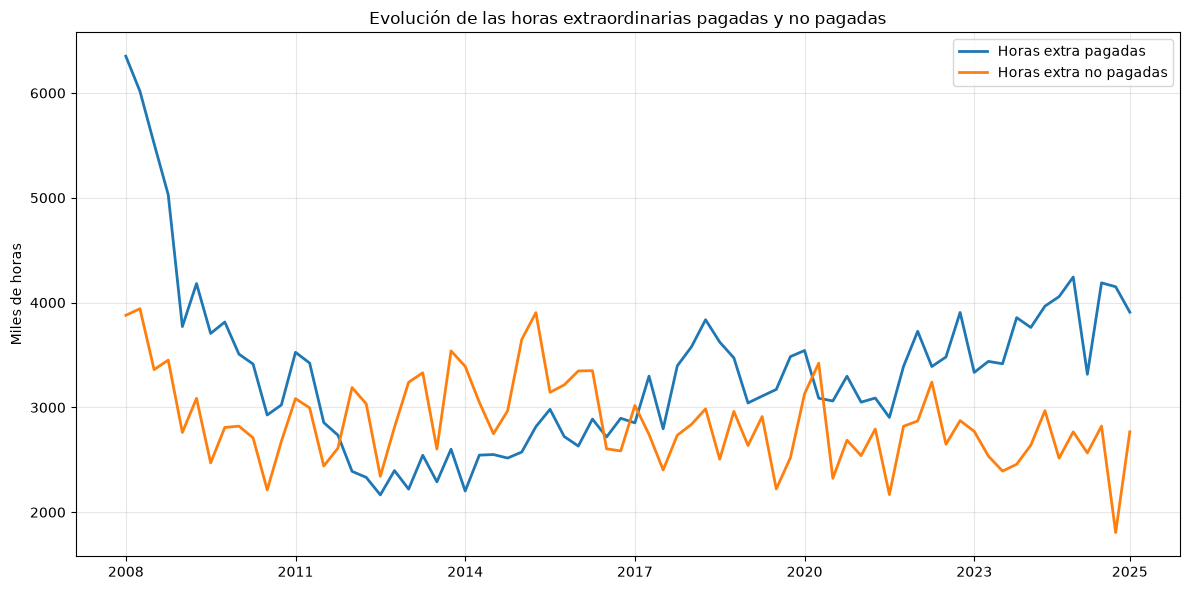

In [84]:
plt.figure(figsize=(12,6))

plt.plot(
    df_pagadas["Total"],
    label="Horas extra pagadas",
    linewidth=2
)

plt.plot(
    df_no_pagadas["Total"],
    label="Horas extra no pagadas",
    linewidth=2
)

ticks = list(range(0, len(df_pagadas), 12))
ticks.append(len(df_pagadas)-1)

plt.xticks(
    ticks=ticks,
    labels=df_pagadas["Año"].iloc[ticks]
)

plt.title("Evolución de las horas extraordinarias pagadas y no pagadas")
plt.ylabel("Miles de horas")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Interpretación

Las horas extraordinarias pagadas muestran una fuerte caída tras la crisis económica de 2008 y posteriormente una recuperación progresiva hasta 2025.

Las horas extraordinarias no pagadas presentan una evolución más estable a lo largo del periodo analizado, manteniéndose alrededor de los dos o tres millones de horas semanales.

La comparación entre ambas series muestra que una parte importante de las horas extraordinarias realizadas continúa sin ser remunerada, incluso en los años más recientes.

## Horas extraordinarias por rama de actividad económica

Para identificar los sectores donde las horas extraordinarias tienen una mayor incidencia, se analizan las ramas de actividad económica durante el último año disponible.


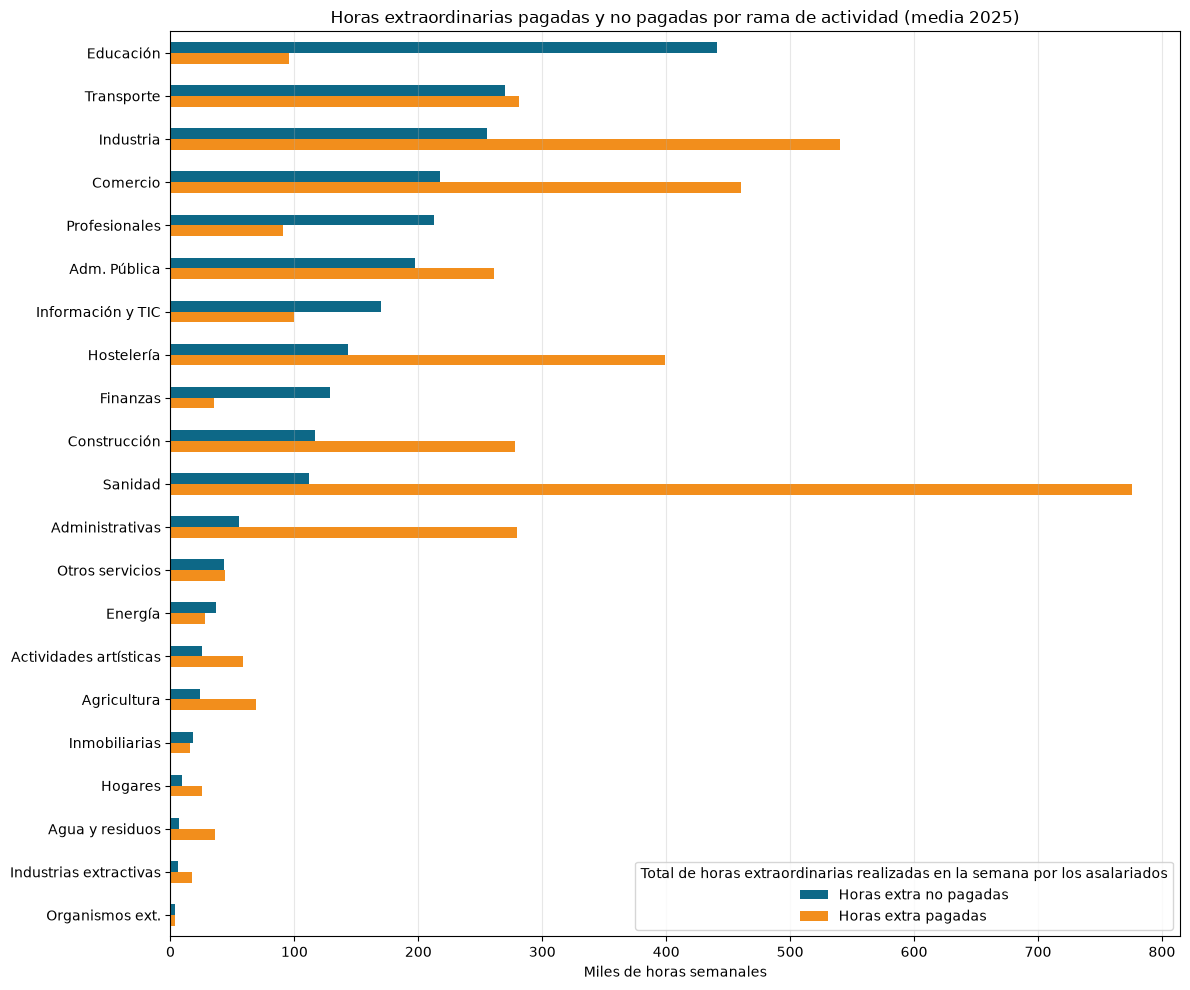

In [85]:
df_2025 = df_horas_clean[
    (df_horas_clean["Sexo"] == "Ambos sexos") &
    (df_horas_clean["Periodo"].str.contains("2025"))
].copy()

tabla_2025 = df_2025.pivot_table(
    index="Rama de actividad CNAE 2009",
    columns="Total de horas extraordinarias realizadas en la semana por los asalariados",
    values="Total",
    aggfunc="mean"
)

tabla_2025 = tabla_2025.drop("Total")

tabla_2025 = tabla_2025.sort_values(
    "Horas extra no pagadas",
    ascending=False
)

abreviaturas = {
    "P Educación": "Educación",
    "H Transporte y almacenamiento": "Transporte",
    "C Industria manufacturera": "Industria",
    "G Comercio al por mayor y al por menor, reparación de vehículos de motor y motocicletas": "Comercio",
    "M Actividades profesionales, científicas y técnicas": "Profesionales",
    "O Administración Pública y defensa, Seguridad Social obligatoria": "Adm. Pública",
    "J Información y comunicaciones": "Información y TIC",
    "I Hostelería": "Hostelería",
    "K Actividades financieras y de seguros": "Finanzas",
    "F Construcción": "Construcción",
    "Q Actividades sanitarias y de servicios sociales": "Sanidad",
    "N Actividades administrativas y servicios auxiliares": "Administrativas",
    "S Otros servicios": "Otros servicios",
    "D Suministro de energía eléctrica, gas, vapor y aire acondicionado": "Energía",
    "R Actividades artísticas, recreativas y de entretenimiento": "Actividades artísticas",
    "A Agricultura, ganadería, silvicultura y pesca": "Agricultura",
    "L Actividades inmobiliarias": "Inmobiliarias",
    "T Actividades de los hogares como empleadores de personal doméstico, actividades de los hogares como productores de bienes y servicios para uso propio": "Hogares",
    "E Suministro de agua, actividades de saneamiento, gestión de residuos y descontaminación": "Agua y residuos",
    "B Industrias extractivas": "Industrias extractivas",
    "U Actividades de organizaciones y organismos extraterritoriales": "Organismos ext."
}

tabla_plot = tabla_2025.copy()
tabla_plot.index = tabla_plot.index.map(lambda x: abreviaturas.get(x, x))

ax = tabla_plot[
    ["Horas extra no pagadas", "Horas extra pagadas"]
].plot(
    kind="barh",
    figsize=(12,10),
    color=["#0D6887", "#F28E1C"]
)

ax.invert_yaxis()

plt.title(
    "Horas extraordinarias pagadas y no pagadas por rama de actividad (media 2025)"
)

plt.xlabel("Miles de horas semanales")
plt.ylabel("")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación

La distribución sectorial de las horas extraordinarias muestra diferencias importantes entre actividades económicas.

La Educación presenta el mayor volumen medio de horas extraordinarias no remuneradas durante 2025, con aproximadamente 440,7 miles de horas semanales. También destacan Transporte y almacenamiento (270 miles de horas), Industria manufacturera (255,3 miles) y Comercio (217,3 miles).

Por su parte, las horas extraordinarias remuneradas tienen una presencia especialmente elevada en sectores como Industria manufacturera, Comercio y Actividades sanitarias y de servicios sociales.

Estos resultados indican que las horas extraordinarias no pagadas no se distribuyen de forma homogénea entre sectores económicos, sino que se concentran especialmente en determinadas ramas de actividad.

# Estadística descriptiva

Una vez analizadas las principales tendencias temporales y sectoriales, se estudian las características generales de los conjuntos de datos mediante medidas descriptivas básicas.

In [86]:
df_asalariados_clean["Total"].describe()

count    18379.000000
mean       615.826285
std       1881.892886
min          0.000000
25%          7.900000
50%         40.500000
75%        523.650000
max      19159.100000
Name: Total, dtype: float64

Los datos muestran una elevada dispersión en el número de asalariados que realizan horas extraordinarias. La media se sitúa en torno a 616 miles de trabajadores, aunque la mediana es considerablemente menor (40,5), lo que indica la existencia de valores muy elevados que aumentan la media.

El valor máximo observado supera los 19 millones de asalariados, mientras que también existen registros con valor cero, reflejando la heterogeneidad de las categorías incluidas en el conjunto de datos.

In [87]:
df_horas_clean["Total"].describe()

count    13309.000000
mean       268.322819
std        689.699261
min          0.000000
25%         21.500000
50%         78.700000
75%        225.900000
max      10230.700000
Name: Total, dtype: float64

Las horas extraordinarias presentan una distribución desigual entre sectores y periodos. La media se sitúa en 268,3 miles de horas, mientras que la mediana alcanza 78,7 miles, lo que vuelve a evidenciar una distribución sesgada por la presencia de valores muy elevados.

El valor máximo supera las 10.200 miles de horas semanales, mientras que numerosos registros presentan cantidades reducidas o incluso nulas.

## Distribución de las horas extraordinarias

Además de las medidas descriptivas, resulta útil visualizar cómo se distribuyen las observaciones dentro del conjunto de datos.

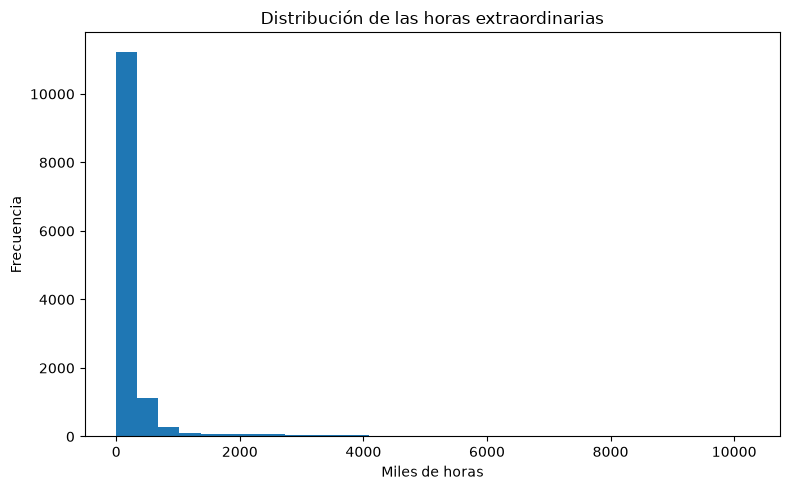

In [88]:
plt.figure(figsize=(8,5))

plt.hist(
    df_horas_clean["Total"].dropna(),
    bins=30
)

plt.title("Distribución de las horas extraordinarias")
plt.xlabel("Miles de horas")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

### Interpretación

La distribución de las horas extraordinarias presenta una fuerte asimetría hacia la derecha. La mayor parte de las observaciones se concentra en valores bajos, mientras que existe un número reducido de registros con cantidades muy elevadas de horas extraordinarias.

Este comportamiento explica la diferencia observada entre la media y la mediana en las estadísticas descriptivas y sugiere la presencia de valores extremos asociados a determinados sectores económicos o agregaciones temporales.

Por tanto, los datos no siguen una distribución uniforme, sino que muestran una elevada concentración en un reducido número de observaciones de gran magnitud.

# Conclusiones

Las hipótesis planteadas al inicio del estudio quedan, en términos generales, confirmadas por los resultados obtenidos:

La primera hipótesis se verifica, ya que el número de asalariados que realizan horas extraordinarias disminuyó notablemente tras la crisis económica de 2008 y posteriormente mostró una recuperación gradual. La segunda hipótesis también queda respaldada por los datos, puesto que las horas extraordinarias no remuneradas mantienen una presencia constante a lo largo de todo el periodo analizado. Por último, el análisis sectorial confirma la existencia de importantes diferencias entre actividades económicas, concentrándose las mayores cantidades de horas extraordinarias no pagadas en sectores como Educación, Transporte e Industria manufacturera.

Asimismo, el análisis por sectores muestra que las horas extraordinarias no pagadas se concentran especialmente en Educación, Transporte y almacenamiento e Industria manufacturera. Estas actividades registran los mayores volúmenes medios de horas extraordinarias no remuneradas durante 2025. Por otra parte, las medidas descriptivas y la distribución observada evidencian una elevada dispersión de los datos. La presencia de valores extremos provoca que la media sea superior a la mediana, reflejando una distribución claramente asimétrica.

En conjunto, los resultados muestran que las horas extraordinarias continúan teniendo un peso significativo en el mercado laboral español y que existen diferencias importantes entre sectores tanto en el volumen de horas realizadas como en su nivel de remuneración.
